# B2: BiGRU / BiLSTM executed walkthrough

Full training: `python scripts/train_b2.py`. This walkthrough inspects those completed runs and executes the saved demo model. It does not launch training again or choose settings from test results.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / "emotionshift").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import torch
from IPython.display import display, Image
from emotionshift.data.loaders import load
from emotionshift.data.labels import EMOTIONS
from emotionshift.models.birnn import BiRNNBaseline
torch.set_num_threads(4)
print("PyTorch", torch.__version__, "labels:", EMOTIONS)

PyTorch 2.15.0+cpu labels: ['neutral', 'joy', 'surprise', 'anger', 'sadness', 'disgust', 'fear']


## Shared data and splits
The official loader supplies labels, same-speaker strata and DailyDialog test_dedup.

In [2]:
counts = []
for dataset in ["meld", "dailydialog"]:
    df = load(dataset)
    table = df.groupby("split").agg(utterances=("text", "size"), dialogues=("dialogue_id", "nunique"))
    counts.append(table.assign(dataset=dataset).reset_index())
display(pd.concat(counts, ignore_index=True))

,split,utterances,dialogues,dataset
0,dev,1109,114,meld
1,test,2610,280,meld
2,train,9989,1038,meld
3,dev,8069,1000,dailydialog
4,test,7740,1000,dailydialog
5,test_dedup,7019,891,dailydialog
6,train,87170,11118,dailydialog


## Architecture and dev checkpoint selection
Train-only vocabulary; learned embeddings; packed sequences; bidirectional final states; dropout; linear head. GRU uses reset/update gates, while LSTM also maintains a cell state. All hyperparameters were fixed before test scoring.

In [3]:
for dataset in ["meld", "dailydialog"]:
    report = ROOT / "reports/b2" / dataset
    display(pd.read_csv(report / "dev_comparison.csv"))
    print(dataset, json.loads((report / "selection.json").read_text()))

,model,architecture,seed,best_epoch,dev_score,selection_metric,train_seconds
0,b2_bigru,gru,0,10,0.522400,weighted_f1,44.994664
1,b2_bigru,gru,1,4,0.510611,weighted_f1,24.048321
2,b2_bigru,gru,2,7,0.521153,weighted_f1,35.417544
3,b2_bigru,gru,3,6,0.509020,weighted_f1,30.610996
4,b2_bigru,gru,4,10,0.522764,weighted_f1,43.077737
5,b2_bilstm,lstm,0,4,0.497438,weighted_f1,25.683664
6,b2_bilstm,lstm,1,4,0.521408,weighted_f1,28.927802
7,b2_bilstm,lstm,2,4,0.502875,weighted_f1,25.747181
8,b2_bilstm,lstm,3,4,0.514825,weighted_f1,27.434848
9,b2_bilstm,lstm,4,6,0.520590,weighted_f1,35.198390


meld {'selected_model': 'b2_bigru', 'metric': 'weighted_f1', 'rule': 'mean best-dev score across seeds; ties follow config order', 'dev_means': {'b2_bigru': 0.5171896793331182, 'b2_bilstm': 0.5114272644804851}, 'test_used_for_selection': False}


,model,architecture,seed,best_epoch,dev_score,selection_metric,train_seconds
0,b2_bigru,gru,0,6,0.523479,micro_f1_no_neutral,389.302106
1,b2_bigru,gru,1,4,0.522262,micro_f1_no_neutral,303.918469
2,b2_bigru,gru,2,6,0.520031,micro_f1_no_neutral,402.502519
3,b2_bigru,gru,3,3,0.521299,micro_f1_no_neutral,268.195425
4,b2_bigru,gru,4,7,0.525171,micro_f1_no_neutral,446.613000
5,b2_bilstm,lstm,0,6,0.532298,micro_f1_no_neutral,437.904446
6,b2_bilstm,lstm,1,3,0.523077,micro_f1_no_neutral,288.208241
7,b2_bilstm,lstm,2,7,0.527881,micro_f1_no_neutral,480.300429
8,b2_bilstm,lstm,3,3,0.523830,micro_f1_no_neutral,293.243938
9,b2_bilstm,lstm,4,3,0.517742,micro_f1_no_neutral,292.991565


dailydialog {'selected_model': 'b2_bilstm', 'metric': 'micro_f1_no_neutral', 'rule': 'mean best-dev score across seeds; ties follow config order', 'dev_means': {'b2_bilstm': 0.5249654271990221, 'b2_bigru': 0.5224484632092108}, 'test_used_for_selection': False}


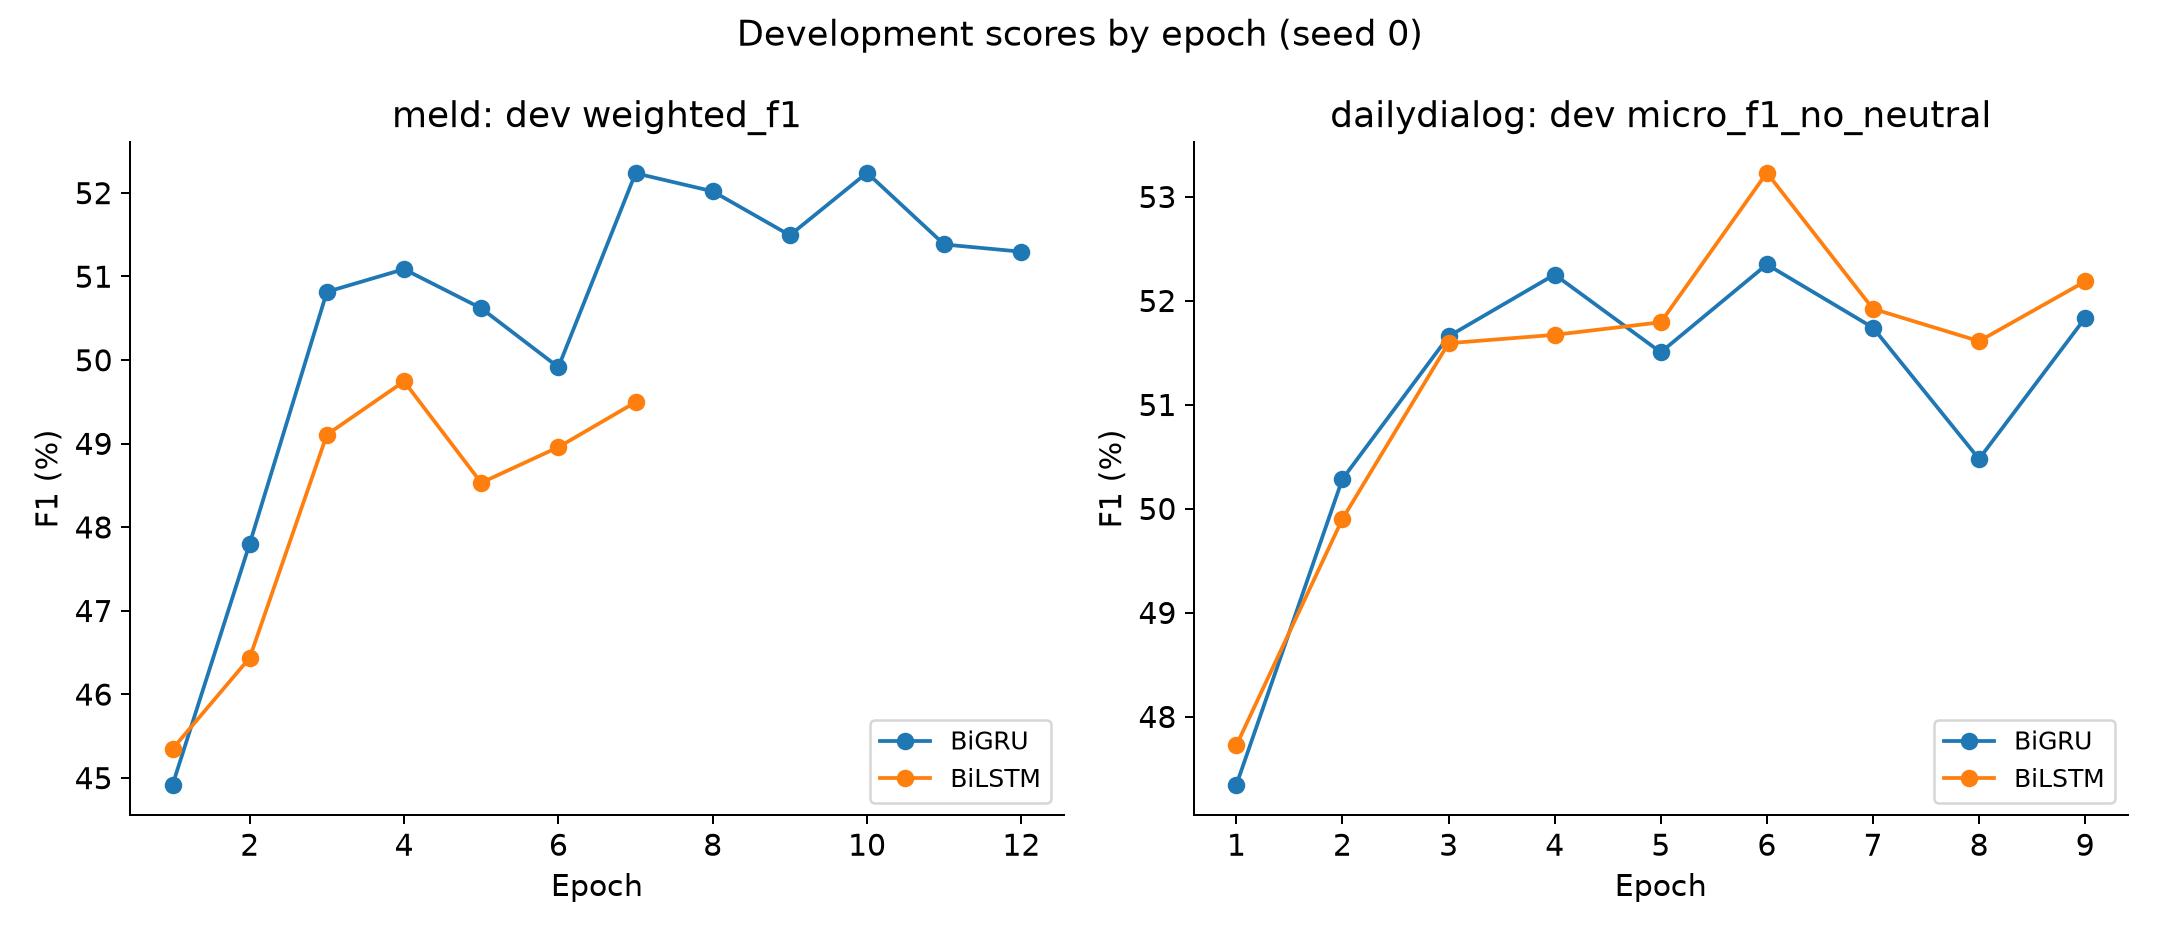

In [4]:
display(Image(filename=str(ROOT / "reports/b2/figures/dev_learning.png")))

## Results and uncertainty
Means and population standard deviations use five seeds. The 95% intervals resample whole dialogues 1,000 times for seed 0 and are not intervals over seeds. DailyDialog test_dedup is the headline; official test is a secondary comparison.

,dataset,model,split,metric,n,mean,std,ci95_seed0_low,ci95_seed0_high,selected_on_dev
0,meld,b2_bigru,test,weighted_f1,2610,0.550837,0.004461,0.524416,0.567318,True
1,meld,b2_bilstm,test,weighted_f1,2610,0.549022,0.004290,0.526064,0.571162,False
2,dailydialog,b2_bigru,test_dedup,micro_f1_no_neutral,7019,0.489526,0.005119,0.468203,0.521032,False
3,dailydialog,b2_bilstm,test_dedup,micro_f1_no_neutral,7019,0.482751,0.007791,0.460427,0.513613,True


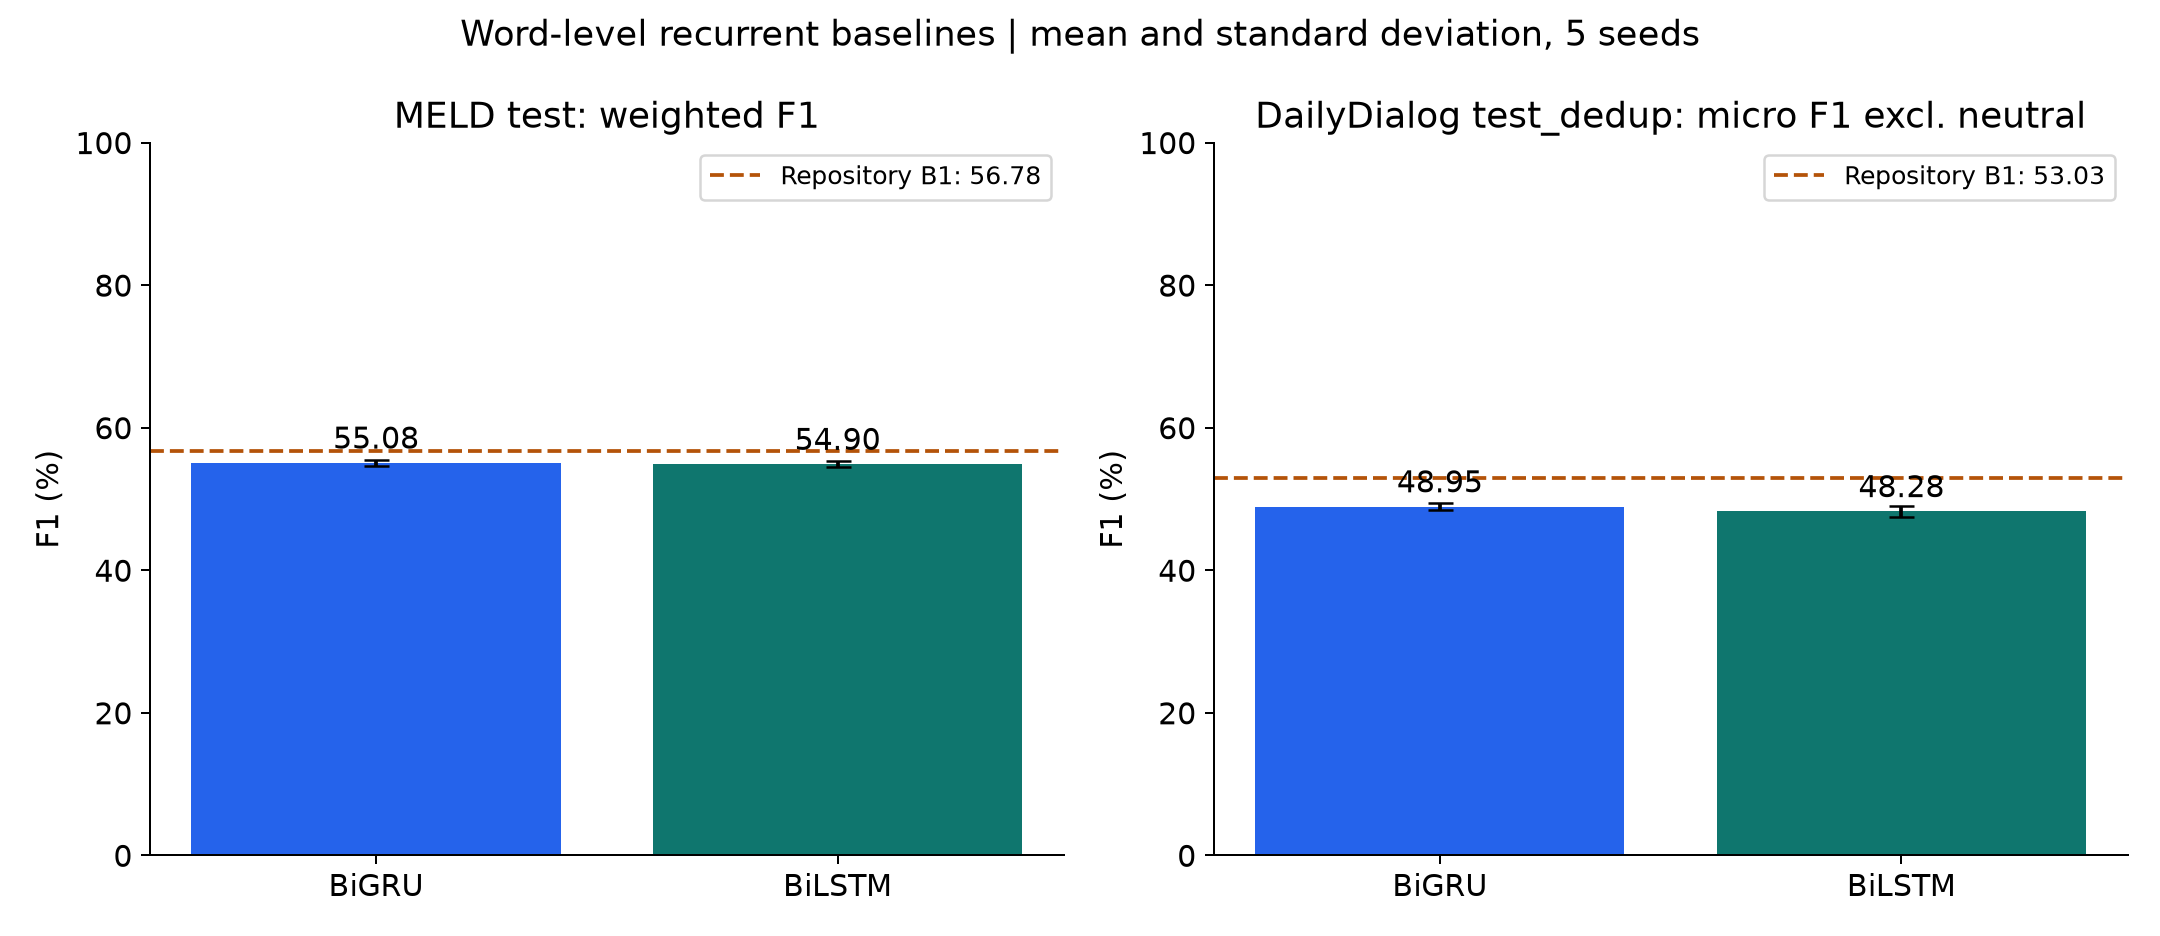

In [5]:
display(pd.read_csv(ROOT / "reports/b2/figures/headline.csv"))
display(Image(filename=str(ROOT / "reports/b2/figures/headline.png")))

## Shared prediction export
Video snippet: the following cell, at most 15 lines.

In [6]:
selection = json.loads((ROOT / "reports/b2/meld/selection.json").read_text())
name = selection["selected_model"]
path = ROOT / "predictions" / f"{name}_meld_test_seed0.csv"
predictions = pd.read_csv(path)
expected = ["dataset", "split", "dialogue_id", "turn", "speaker", "text",
            "emotion", "pred", "stratum", "shift_type", "model", "seed"]
assert predictions.columns.tolist() == expected
assert len(predictions) == 2610
assert set(predictions.pred) <= set(EMOTIONS)
display(predictions.head(3))

,dataset,split,dialogue_id,turn,speaker,text,emotion,pred,stratum,shift_type,model,seed
0,meld,test,0,0,Mark,Why do all you're coffee mugs have numbers on ...,surprise,neutral,first,NaN,b2_bigru,0
1,meld,test,0,1,Rachel,Oh. That's so Monica can keep track. That way ...,anger,joy,first,NaN,b2_bigru,0
2,meld,test,0,2,Rachel,Y'know what?,neutral,neutral,shift,offset,b2_bigru,0


## Demo interface
Video snippet: the following cell, at most 15 lines. These invented utterances are interface examples, not an accuracy estimate.

In [7]:
model = BiRNNBaseline.load(ROOT / "models" / f"{name}_meld_seed0.pt")
texts = ["Oh my God!", "Yeah.", "I am so sorry."]
print(model.network)
proba = model.predict_proba(texts)
display(pd.DataFrame(proba, columns=EMOTIONS).assign(text=texts, pred=model.predict(texts)))
print("Checkpoint epoch:", model.best_epoch, "dev score:", model.best_dev_score)

_Encoder(
  (embedding): Embedding(2700, 64, padding_idx=0)
  (dropout): Dropout(p=0.3, inplace=False)
  (rnn): GRU(64, 64, batch_first=True, bidirectional=True)
  (output): Linear(in_features=128, out_features=7, bias=True)
)


,neutral,joy,surprise,anger,sadness,disgust,fear,text,pred
0,0.000366,0.014207,0.954957,0.008942,0.007933,0.009339,0.004255,Oh my God!,surprise
1,0.855309,0.042864,0.008536,0.014552,0.032419,0.039095,0.007225,Yeah.,neutral
2,0.013166,0.011465,0.002493,0.002939,0.941694,0.000874,0.027368,I am so sorry.,sadness


Checkpoint epoch: 10 dev score: 0.5224002394120522


## Same-speaker shift analysis
Gold emotion/shift labels are used only for evaluation. Inference accepts text alone; derived shift detection compares current and previous predicted emotions.

,dataset,model,split,group,n,metric,f1
0,meld,b2_bigru,test,stratum:first,746,weighted_f1,0.589813
1,meld,b2_bigru,test,stratum:stable,861,weighted_f1,0.621205
2,meld,b2_bigru,test,stratum:shift,1003,weighted_f1,0.471922
3,meld,b2_bilstm,test,stratum:first,746,weighted_f1,0.591524
4,meld,b2_bilstm,test,stratum:stable,861,weighted_f1,0.633379
5,meld,b2_bilstm,test,stratum:shift,1003,weighted_f1,0.456246
6,dailydialog,b2_bigru,test_dedup,stratum:first,1782,micro_f1_no_neutral,0.442152
7,dailydialog,b2_bigru,test_dedup,stratum:stable,4295,micro_f1_no_neutral,0.301701
8,dailydialog,b2_bigru,test_dedup,stratum:shift,942,micro_f1_no_neutral,0.716368
9,dailydialog,b2_bilstm,test_dedup,stratum:first,1782,micro_f1_no_neutral,0.416621


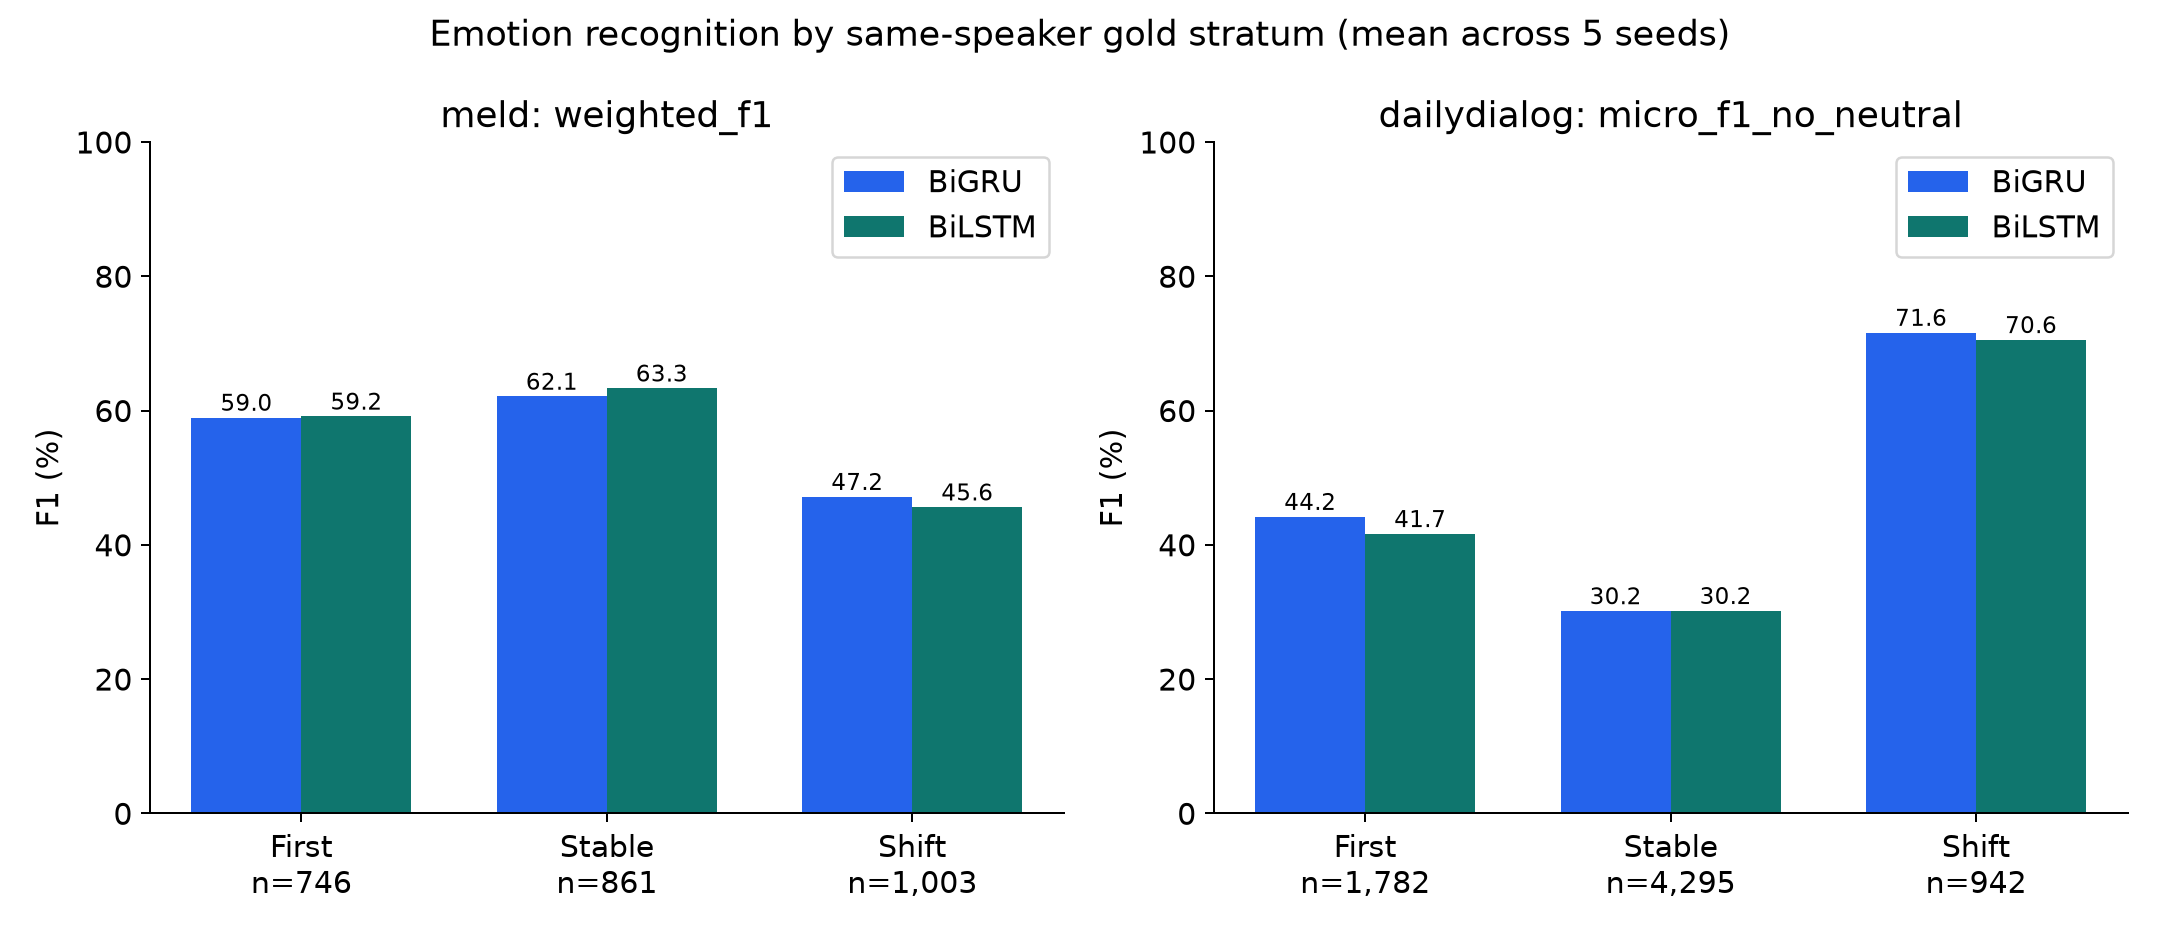

In [8]:
display(pd.read_csv(ROOT / "reports/b2/figures/strata.csv"))
display(Image(filename=str(ROOT / "reports/b2/figures/strata.png")))

## Efficiency and limits
Models learn embeddings from scratch and truncate at 64 tokens. They omit conversation history, speakers, audio and images. Probability outputs are softmax values, not calibrated confidence estimates. Exact timings depend on CPU and thread settings.

In [9]:
for dataset in ["meld", "dailydialog"]:
    for arch in ["gru", "lstm"]:
        s = json.loads((ROOT / f"reports/b2/{dataset}/b2_bi{arch}/summary.json").read_text())
        e = s["efficiency"]
        print(dataset, arch, {k: e[k] for k in ["parameters", "model_file_mb", "train_seconds", "latency_one_utterance"]})

meld gru {'parameters': 223623, 'model_file_mb': 0.951054, 'train_seconds': {'per_seed': [44.994664300000295, 24.048320599998988, 35.417544000003545, 30.61099639999884, 43.077736999999615], 'mean': 35.62985246000026}, 'latency_one_utterance': {'n': 500, 'median_ms': 0.9774999962246511, 'p95_ms': 2.1194699980696883}}
meld lstm {'parameters': 240263, 'model_file_mb': 1.016863, 'train_seconds': {'per_seed': [25.68366380000225, 28.9278020999991, 25.747181399994588, 27.434848200005945, 35.19839000000502], 'mean': 28.59837710000138}, 'latency_one_utterance': {'n': 500, 'median_ms': 0.9533500015095342, 'p95_ms': 2.26512500194076}}
dailydialog gru {'parameters': 831623, 'model_file_mb': 3.573765, 'train_seconds': {'per_seed': [389.3021058999948, 303.9184685, 402.50251879999996, 268.19542450000154, 446.61299969999527], 'mean': 362.1063034799983}, 'latency_one_utterance': {'n': 500, 'median_ms': 1.09859999793116, 'p95_ms': 2.384084994992008}}
dailydialog lstm {'parameters': 848263, 'model_file_m

## References
See `deliverables/03_thanh/refs.txt` for APA references to GRU, LSTM, bidirectional RNN, MELD and DailyDialog.

AI assistance was used for implementation and preparation. Review, explain and disclose it per the team guide.